## Setup — import libraries and find the shared data folder

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the shared data folder from the repository root or app/L8.
def data_path(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        file = folder / "data" / filename
        if file.is_file():
            return file
    raise FileNotFoundError(f"Cannot find {filename} from {Path.cwd()}")

## 1. Open the image as a NumPy array

A grayscale image is a 2D grid of pixel intensities.

In [2]:
from PIL import Image
import numpy as np
image = np.array(Image.open(data_path("coins.png")).convert("L"))
print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())

Image shape: (303, 384)
Pixel range: 1 to 252


## 2. Display the original image

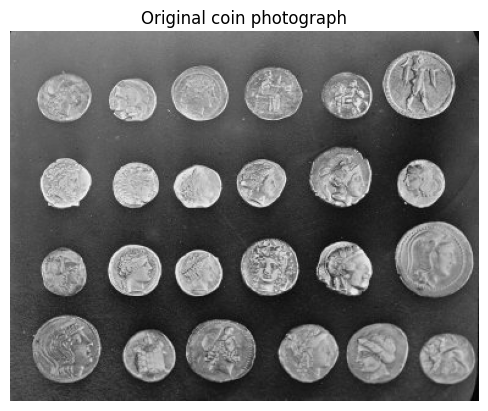

In [3]:
plt.imshow(image, cmap="gray")
plt.title("Original coin photograph")
plt.axis("off")
plt.show()

## 3. Apply a colour map

A colour map changes the **display**, not the underlying pixels.

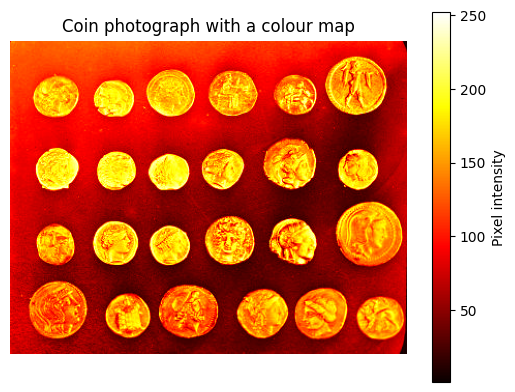

In [4]:
plt.imshow(image, cmap="hot")
plt.title("Coin photograph with a colour map")
plt.colorbar(label="Pixel intensity")
plt.axis("off")
plt.show()

## 4. Zoom in on a small region

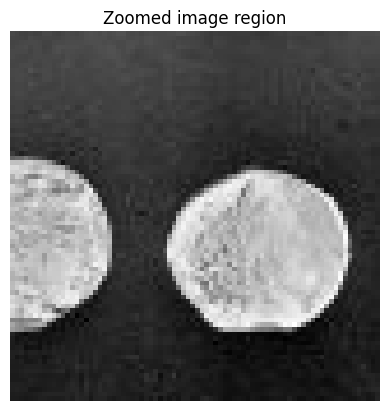

In [5]:
crop = image[80:160, 100:180]
plt.imshow(crop, cmap="gray")
plt.title("Zoomed image region")
plt.axis("off")
plt.show()

## 5. Compare nearest and bilinear interpolation

Interpolation changes how pixels are **displayed when enlarged**. It does not restore missing detail.

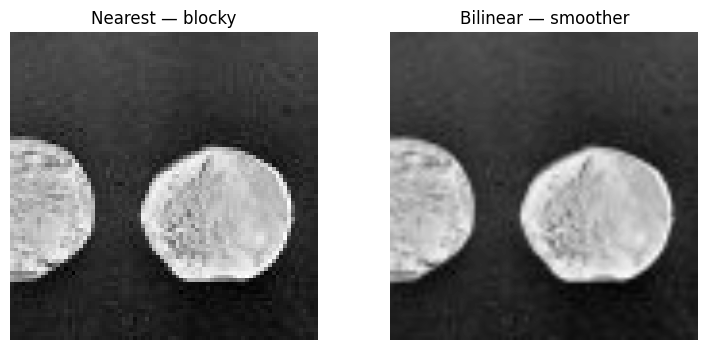

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(crop, cmap="gray", interpolation="nearest")
axes[0].set_title("Nearest — blocky")
axes[1].imshow(crop, cmap="gray", interpolation="bilinear")
axes[1].set_title("Bilinear — smoother")
for ax in axes:
    ax.axis("off")
plt.show()

## 6. Histogram — how bright are the pixels?

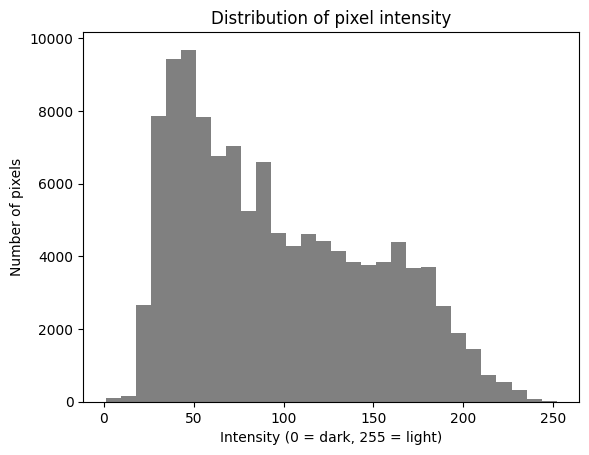

In [7]:
plt.hist(image.ravel(), bins=30, color="gray")
plt.title("Distribution of pixel intensity")
plt.xlabel("Intensity (0 = dark, 255 = light)")
plt.ylabel("Number of pixels")
plt.show()

### Discuss

Does a `hot` colour map prove the coin is hotter? Why not? How can interpolation change the viewer’s impression without adding information?

## Your turn — short challenges

1. Change the colour map from `"hot"` to `"viridis"`.
2. Crop a different region: `image[30:130, 180:280]`.
3. Compare the two interpolation options on that crop.

In [8]:
# Write your solution here.
# Start by changing one line from an example above.